# Machine Learning Lab: DBSCAN Clustering
## Wholesale Customers Dataset

**Aim**

Apply DBSCAN to the Wholesale Customers dataset, select a suitable `eps` value using a sorted k-distance graph, identify noise points, and compare the outcome with a K-Means reference model.

**Objectives**

1. Inspect the customer spending data and prepare numerical features for distance-based clustering.
2. Construct a k-distance graph to guide the selection of `eps`.
3. Apply DBSCAN and identify clusters and noise observations.
4. Examine the spending profiles of observations classified as noise.
5. Compare DBSCAN with K-Means using the same transformed and standardized features.

**Dataset**

The file contains 440 customers, two coded descriptors (`Channel` and `Region`), and six annual spending variables. The six spending variables are used as clustering inputs. `Channel` and `Region` are kept aside for context and are not used to calculate distances.

**Comparison note**

The earlier Wholesale Customers report available in this conversation used Spectral Clustering on a 10-nearest-neighbor graph. It was not a K-Means experiment. To avoid describing that method incorrectly, this notebook includes a freshly fitted K-Means reference model with `k=2`, using the same input features and preprocessing. The earlier Spectral Clustering result is identified separately in the comparison section.

## 1. Import libraries

The first cell loads the libraries required for data inspection, numerical transformations, nearest-neighbor distance calculations, clustering, dimensionality reduction, and plotting.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, KMeans, SpectralClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 10})

## 2. Load and inspect the dataset

The CSV file is read into a DataFrame. The initial checks show the number of customer records, field names, data types, and a small sample of rows. This confirms which columns are available before selecting the spending variables.

In [2]:
file_path = "Wholesale customers data.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes.to_string())
print("\nFirst five records:")
print(df.head().to_string(index=False))

Dataset shape: (440, 8)

Column names:
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

Data types:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64

First five records:
 Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
       2       3  12669  9656     7561     214              2674        1338
       2       3   7057  9810     9568    1762              3293        1776
       2       3   6353  8808     7684    2405              3516        7844
       1       3  13265  1196     4221    6404               507        1788
       2       3  22615  5410     7198    3915              1777        5185


## 3. Data quality and feature selection

The dataset is checked for missing values and exact duplicate rows. The clustering matrix contains only the six annual spending measures. `Channel` and `Region` are excluded because they are coded categorical descriptors, not spending magnitudes. They remain in the original DataFrame for later reference.

In [3]:
spend_cols = [
    "Fresh", "Milk", "Grocery", "Frozen",
    "Detergents_Paper", "Delicassen"
]

print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nTotal missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("\nSummary of spending features:")
print(df[spend_cols].describe().round(1).to_string())

X_raw = df[spend_cols].copy()
print("\nClustering matrix shape:", X_raw.shape)

Missing values per column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0

Total missing values: 0
Exact duplicate rows: 0

Summary of spending features:
          Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen
count     440.0    440.0    440.0    440.0             440.0       440.0
mean    12000.3   5796.3   7951.3   3071.9            2881.5      1524.9
std     12647.3   7380.4   9503.2   4854.7            4767.9      2820.1
min         3.0     55.0      3.0     25.0               3.0         3.0
25%      3127.8   1533.0   2153.0    742.2             256.8       408.2
50%      8504.0   3627.0   4755.5   1526.0             816.5       965.5
75%     16933.8   7190.2  10655.8   3554.2            3922.0      1820.2
max    112151.0  73498.0  92780.0  60869.0           40827.0     47943.0

Clustering matrix shape: (440, 6)


## 4. Inspect spending distributions

Annual spending varies considerably between customers and across product categories. Histograms are plotted to show the distribution of each input feature. The strong right-skew in several columns is one reason a logarithmic transformation is applied before distance calculations.

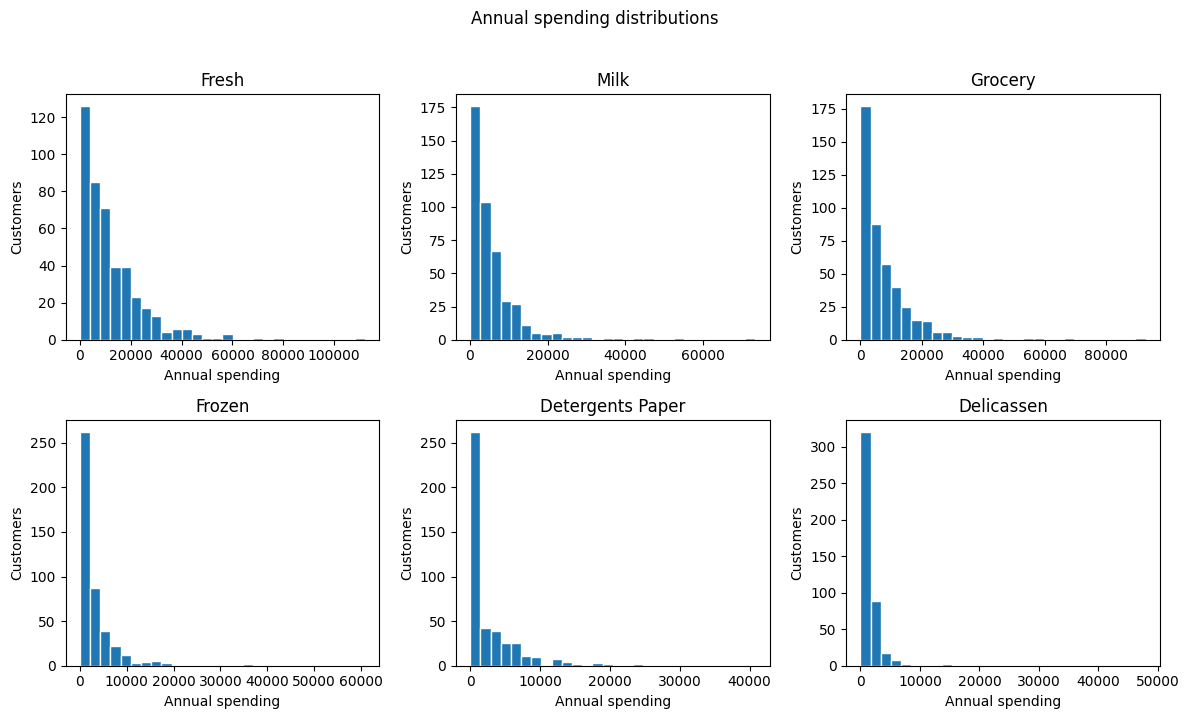

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, spend_cols):
    ax.hist(X_raw[col], bins=28, edgecolor="white")
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel("Annual spending")
    ax.set_ylabel("Customers")
fig.suptitle("Annual spending distributions", y=1.02)
plt.tight_layout()
plt.show()

## 5. Transform and standardize the features

DBSCAN uses distances to identify dense neighborhoods. Spending variables with large ranges could dominate those distances, so the six spending columns are first transformed with `log1p` to reduce skew. `StandardScaler` then puts the transformed features on comparable scales.

The same preprocessing is used for the K-Means reference model and matches the preparation used in the earlier nearest-neighbor graph report. This makes the algorithm comparison more consistent.

In [5]:
X_log = np.log1p(X_raw)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Rows used:", X_scaled.shape[0])
print("Features used:", X_scaled.shape[1])
print("Missing values in clustering matrix:", int(X_raw.isna().sum().sum()))
print("Scaled feature means:", np.round(X_scaled.mean(axis=0), 3))
print("Scaled feature standard deviations:", np.round(X_scaled.std(axis=0), 3))

Rows used: 440
Features used: 6
Missing values in clustering matrix: 0
Scaled feature means: [ 0. -0. -0.  0. -0. -0.]
Scaled feature standard deviations: [1. 1. 1. 1. 1. 1.]


## 6. Build the sorted k-distance graph

The `eps` parameter defines the neighborhood radius used by DBSCAN. A k-distance graph helps choose a reasonable radius by plotting each observation's distance to its k-th nearest neighbor, after sorting the distances from smallest to largest.

Here, `min_samples=10` is used. The tenth-neighbor distance is calculated for every customer and sorted. The point where the curve begins to rise sharply provides a visual guide for choosing `eps`. The plot is interpreted in the standardized feature space, so the distance has no direct spending-unit interpretation.

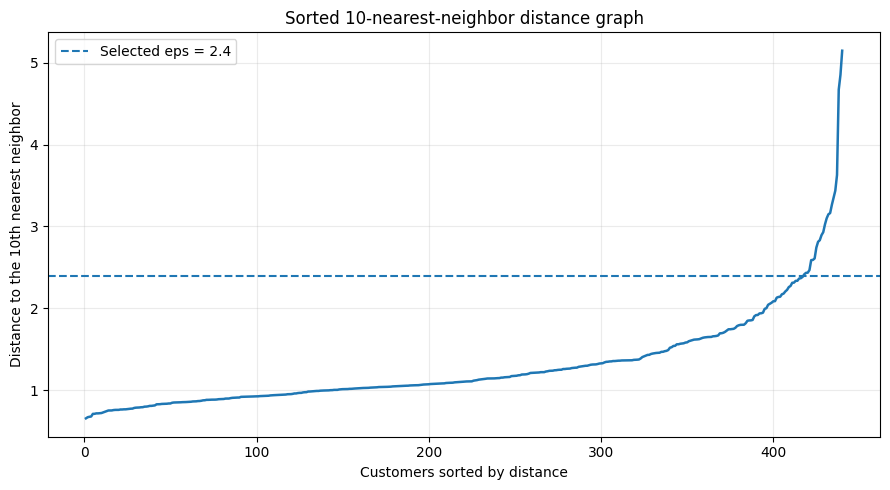

min_samples: 10
Selected eps: 2.4
Distance at the 95th percentile: 2.416


In [6]:
min_samples = 10
nearest = NearestNeighbors(n_neighbors=min_samples, metric="euclidean")
nearest.fit(X_scaled)
distances, neighbor_indices = nearest.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

# Visual inspection of the sharp upturn suggests an eps near 2.4.
eps_selected = 2.4

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(k_distances) + 1), k_distances, linewidth=1.8)
plt.axhline(eps_selected, linestyle="--", linewidth=1.5,
            label=f"Selected eps = {eps_selected}")
plt.title("Sorted 10-nearest-neighbor distance graph")
plt.xlabel("Customers sorted by distance")
plt.ylabel("Distance to the 10th nearest neighbor")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("min_samples:", min_samples)
print("Selected eps:", eps_selected)
print("Distance at the 95th percentile:", round(float(np.percentile(k_distances, 95)), 3))

## 7. Check the effect of different epsilon values

The k-distance graph gives a starting point, but the result should also be checked against nearby radius values. The table below records the number of clusters and the number of points labelled as noise for a small range of `eps` values. This makes the trade-off visible: a radius that is too small can classify most observations as noise, while a larger radius can connect most observations into one dense group.

In [7]:
eps_values = [0.8, 0.9, 1.0, 1.2, 1.6, 2.0, 2.4]
sensitivity_rows = []

for eps_value in eps_values:
    trial_labels = DBSCAN(eps=eps_value, min_samples=min_samples).fit_predict(X_scaled)
    cluster_ids = set(trial_labels) - {-1}
    noise_count = int(np.sum(trial_labels == -1))
    sensitivity_rows.append({
        "eps": eps_value,
        "clusters": len(cluster_ids),
        "noise_points": noise_count,
        "noise_percent": 100 * noise_count / len(trial_labels)
    })

sensitivity = pd.DataFrame(sensitivity_rows)
print(sensitivity.to_string(index=False, formatters={
    "eps": "{:.2f}".format,
    "noise_percent": "{:.1f}%".format
}))

 eps  clusters  noise_points noise_percent
0.80         2           334         75.9%
0.90         2           248         56.4%
1.00         1           170         38.6%
1.20         1            94         21.4%
1.60         1            41          9.3%
2.00         1            16          3.6%
2.40         1             8          1.8%


## 8. Fit the final DBSCAN model

The selected configuration uses `eps=2.4` and `min_samples=10`. DBSCAN assigns a cluster label to observations that belong to a density-connected region. Points that do not satisfy the density requirement receive label `-1`, which denotes noise.

Unlike K-Means, DBSCAN does not require the number of clusters to be specified in advance. The resulting number of clusters is determined by the density structure in the data.

In [8]:
dbscan = DBSCAN(eps=eps_selected, min_samples=min_samples, metric="euclidean")
dbscan_labels = dbscan.fit_predict(X_scaled)

dbscan_clustered = df.copy()
dbscan_clustered["DBSCAN_Label"] = dbscan_labels

cluster_ids = sorted(set(dbscan_labels) - {-1})
noise_mask = dbscan_labels == -1
noise_count = int(noise_mask.sum())
noise_percent = 100 * noise_count / len(dbscan_labels)

print("Clusters found (excluding noise):", len(cluster_ids))
print("Noise observations:", noise_count)
print("Noise percentage:", round(noise_percent, 2), "%")
print("\nLabel counts:")
print(dbscan_clustered["DBSCAN_Label"].value_counts().sort_index().to_string())

Clusters found (excluding noise): 1
Noise observations: 8
Noise percentage: 1.82 %

Label counts:
DBSCAN_Label
-1      8
 0    432


## 9. Examine noise observations

Noise points are observations that DBSCAN could not assign to a sufficiently dense neighborhood. They are potential outliers under the selected density settings, but they are not automatically errors or invalid records.

The following comparison reports average spending among the noise observations and the main DBSCAN cluster. A bar chart presents the same figures by spending category. The row indices are also listed so that the noise assignments can be traced to the original records.

Mean annual spending: noise points versus clustered customers
                  Noise mean  Cluster mean
Fresh                 7581.1       12082.1
Milk                  3747.5        5834.2
Grocery               5340.6        7999.6
Frozen                3763.0        3059.1
Detergents_Paper      1032.1        2915.7
Delicassen             284.8        1547.8

Noise row indices:
[66, 75, 95, 128, 142, 154, 187, 338]


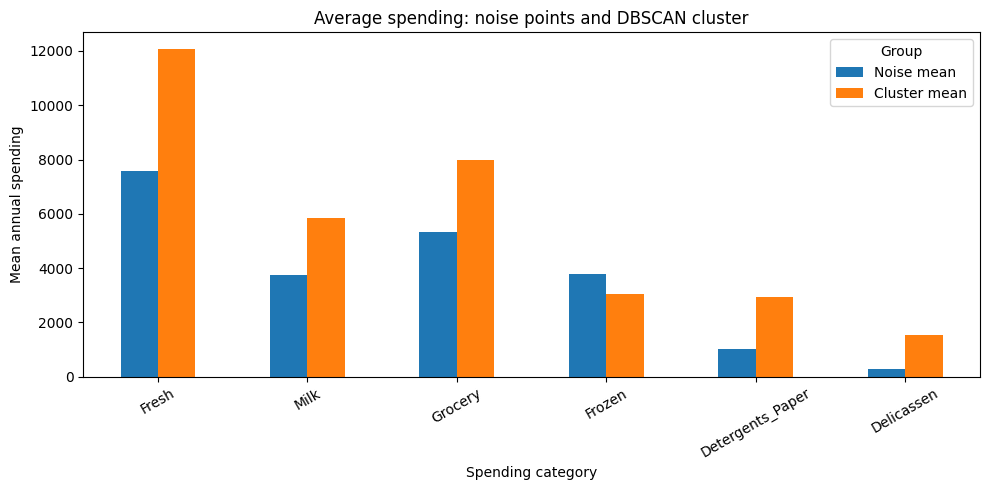

In [9]:
noise_profile = X_raw.loc[noise_mask].mean()
core_profile = X_raw.loc[~noise_mask].mean()
profile_comparison = pd.DataFrame({
    "Noise mean": noise_profile,
    "Cluster mean": core_profile
}).round(1)

print("Mean annual spending: noise points versus clustered customers")
print(profile_comparison.to_string())
print("\nNoise row indices:")
print(np.flatnonzero(noise_mask).tolist())

ax = profile_comparison.plot(kind="bar", figsize=(10, 5))
ax.set_title("Average spending: noise points and DBSCAN cluster")
ax.set_xlabel("Spending category")
ax.set_ylabel("Mean annual spending")
ax.tick_params(axis="x", rotation=30)
ax.legend(title="Group")
plt.tight_layout()
plt.show()

## 10. Visualize DBSCAN assignments with PCA

The model operates on all six standardized spending features. PCA is used only to project those six dimensions into two components for plotting. The projection provides a compact view of the assigned cluster and noise observations, but it does not replace the six-dimensional distance calculations used by DBSCAN.

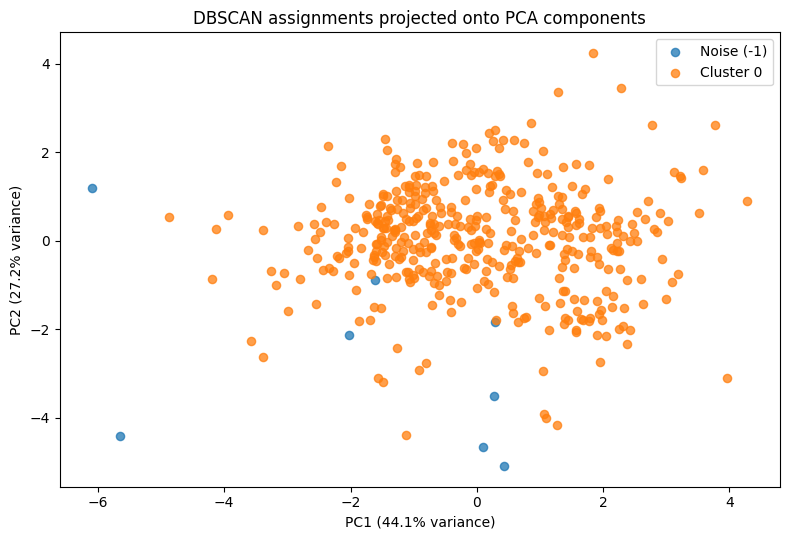

Variance explained by the first two components: 0.713


In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5.5))
for label in sorted(set(dbscan_labels)):
    mask = dbscan_labels == label
    name = "Noise (-1)" if label == -1 else f"Cluster {label}"
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=35, alpha=0.75, label=name)
plt.title("DBSCAN assignments projected onto PCA components")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)")
plt.legend()
plt.tight_layout()
plt.show()

print("Variance explained by the first two components:",
      round(float(pca.explained_variance_ratio_.sum()), 3))

## 11. Fit a K-Means reference model

K-Means is included as a comparison model using the same six log-transformed and standardized spending features. The earlier nearest-neighbor graph report selected two groups, so `k=2` is used here to keep the comparison at a common cluster count. K-Means assigns every observation to one of its clusters and does not mark points as noise.

This is a new K-Means reference run for this comparison. It is not presented as an output from the earlier report, which used Spectral Clustering.

In [11]:
kmeans = KMeans(n_clusters=2, n_init=20, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_sizes = pd.Series(kmeans_labels).value_counts().sort_index()

print("K-Means cluster count:", len(np.unique(kmeans_labels)))
print("K-Means silhouette score:", round(float(kmeans_silhouette), 4))
print("K-Means cluster sizes:")
print(kmeans_sizes.to_string())
print("Noise observations assigned by K-Means: 0")

K-Means cluster count: 2
K-Means silhouette score: 0.2903
K-Means cluster sizes:
0    252
1    188
Noise observations assigned by K-Means: 0


## 12. Compare DBSCAN and K-Means

The comparison focuses on how the two algorithms assign customers. K-Means produces two complete partitions because every observation is assigned to a centroid. DBSCAN identifies one density-connected cluster at the selected radius and marks a small number of isolated observations as noise.

A conventional silhouette score requires at least two clusters. Since the final DBSCAN result contains only one non-noise cluster, a silhouette score for its clustered observations is not defined. It is therefore reported as not applicable rather than treating the noise label as an ordinary cluster.

In [12]:
dbscan_cluster_count = len(set(dbscan_labels) - {-1})
comparison = pd.DataFrame([
    {
        "Method": "DBSCAN (eps=2.4, min_samples=10)",
        "Clusters": dbscan_cluster_count,
        "Noise points": noise_count,
        "Noise (%)": round(noise_percent, 1),
        "Silhouette": "Not defined" if dbscan_cluster_count < 2 else round(
            silhouette_score(X_scaled[~noise_mask], dbscan_labels[~noise_mask]), 4)
    },
    {
        "Method": "K-Means (k=2)",
        "Clusters": 2,
        "Noise points": 0,
        "Noise (%)": 0.0,
        "Silhouette": round(float(kmeans_silhouette), 4)
    }
])
print(comparison.to_string(index=False))

                          Method  Clusters  Noise points  Noise (%)  Silhouette
DBSCAN (eps=2.4, min_samples=10)         1             8        1.8 Not defined
                   K-Means (k=2)         2             0        0.0      0.2903


## 13. Compare the cluster assignments visually

Both methods are shown in the same PCA projection so that the partitioning patterns can be compared on the same axes. DBSCAN marks noise separately, while K-Means divides all customers into two groups. PCA is used for display only. Both algorithms were fitted using all six standardized spending features.

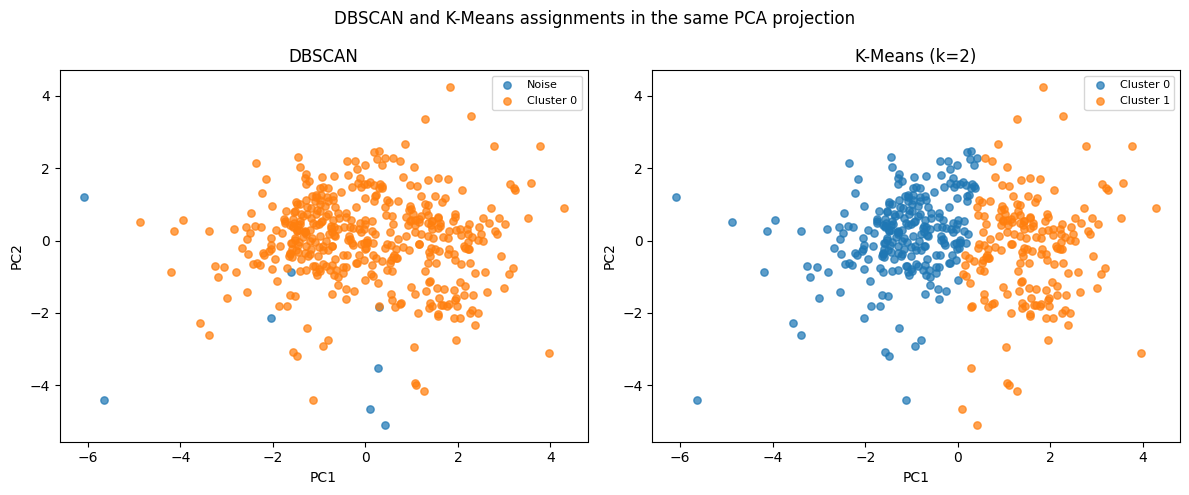

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for label in sorted(set(dbscan_labels)):
    mask = dbscan_labels == label
    name = "Noise" if label == -1 else f"Cluster {label}"
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=28, alpha=0.72, label=name)
axes[0].set_title("DBSCAN")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(fontsize=8)

for label in sorted(np.unique(kmeans_labels)):
    mask = kmeans_labels == label
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=28, alpha=0.72, label=f"Cluster {label}")
axes[1].set_title("K-Means (k=2)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend(fontsize=8)

fig.suptitle("DBSCAN and K-Means assignments in the same PCA projection")
plt.tight_layout()
plt.show()

## 14. Reference to the earlier nearest-neighbor graph experiment

The previously saved Wholesale Customers report used a 10-nearest-neighbor affinity graph followed by Spectral Clustering. Its best tested solution contained two groups of 181 and 259 customers, with a silhouette score of 0.2887. This result is included as context because it used the same six spending variables and the same log transformation and standardization.

It is a Spectral Clustering result, not a K-Means result. The current K-Means reference is fitted separately above.

In [14]:
previous_graph_result = pd.DataFrame([
    {"Method": "Previous Spectral Clustering", "Clusters": 2,
     "Cluster sizes": "181, 259", "Noise points": 0,
     "Silhouette": 0.2887},
    {"Method": "Current K-Means reference", "Clusters": 2,
     "Cluster sizes": ", ".join(map(str, kmeans_sizes.tolist())), "Noise points": 0,
     "Silhouette": round(float(kmeans_silhouette), 4)},
    {"Method": "Current DBSCAN", "Clusters": dbscan_cluster_count,
     "Cluster sizes": ", ".join(map(str, pd.Series(dbscan_labels[~noise_mask]).value_counts().tolist())),
     "Noise points": noise_count,
     "Silhouette": "Not defined" if dbscan_cluster_count < 2 else round(
         silhouette_score(X_scaled[~noise_mask], dbscan_labels[~noise_mask]), 4)}
])
print(previous_graph_result.to_string(index=False))

                      Method  Clusters Cluster sizes  Noise points  Silhouette
Previous Spectral Clustering         2      181, 259             0      0.2887
   Current K-Means reference         2      252, 188             0      0.2903
              Current DBSCAN         1           432             8 Not defined


## 15. Findings and interpretation

- The six spending features were log-transformed and standardized before distance-based clustering.
- The sorted 10-nearest-neighbor distance graph showed a sharp rise near the upper end. A value of `eps=2.4` was selected from this upturn with `min_samples=10`.
- At the selected settings, DBSCAN identified one dense cluster and marked a small number of customers as noise. These observations are unusual relative to the density structure, not necessarily erroneous records.
- Smaller `eps` values generated more clusters but also labelled a much larger share of the dataset as noise. The sensitivity table demonstrates this trade-off.
- K-Means with `k=2` divided all 440 customers into two groups and achieved a silhouette score of approximately 0.2903.
- The DBSCAN result has no valid conventional silhouette score because only one non-noise cluster was found.

## Limitations

DBSCAN is sensitive to `eps`, `min_samples`, feature scaling, and the density distribution of the data. In six dimensions, density can be difficult to separate cleanly. The selected settings produce an effective noise screen but do not recover multiple customer segments. K-Means forces every record into a cluster, while DBSCAN can leave observations unassigned as noise.

## 16. Conclusion

DBSCAN was applied to the Wholesale Customers dataset using six annual spending measures. A log transformation and standardization were used before constructing the k-distance graph. The sharp upper-end increase in the sorted 10-nearest-neighbor distances guided the choice of `eps=2.4`, with `min_samples=10`.

The final DBSCAN model identified one density-connected group and a small set of noise observations. The comparison with a K-Means reference showed the difference between density-based clustering, which can leave isolated records unassigned, and centroid-based clustering, which assigns every record to a group. On this dataset, the selected DBSCAN settings were more useful for detecting isolated spending profiles than for producing several customer segments.

The earlier Wholesale Customers graph-based report used Spectral Clustering, not K-Means. Its two-cluster result is retained as a separate reference to keep the comparison accurate.